# Improved Byte-Level Transformer / Landmark-Attention Notebook (IMDb, 4,000 bytes)

**What was changed versus `Text_Baseline_.ipynb`, and why it should raise accuracy**

| # | Problem in the old notebook | Fix in this notebook |
|---|---|---|
| 1 | Landmarks were **single bytes** picked from all 4,000 positions. For a ~1,300-byte review about two thirds of the fixed landmarks fell on padding and were masked, and each remaining landmark saw only one byte. | Landmarks are **segment means** over the *valid* part of the review (Nyströmformer-style pooling, mentioned in the base paper's related work). Every byte contributes and no landmark is wasted on padding. |
| 2 | Adaptive attention used a slow Python loop over the batch. | Fully **vectorised** landmark selection for fixed and adaptive models. |
| 3 | The method was only "CUR-inspired": the real `C·U⁺·R·V` reconstruction from the base paper was missing. | Added a **paper-style CUR attention** (Algorithm 1: `C`, `R`, `U`, iterative pseudo-inverse) as a fourth model. |
| 4 | Raw bytes only; one byte carries almost no meaning. | A small **causal-free 1-D conv stem** gives every position local n-gram context before attention. It is shared by all four models, so the comparison stays fair. |
| 5 | `<br />` tags and mixed case wasted input bytes. | Text cleaning (HTML tags removed, lower-casing). Long reviews keep **head + tail** (the verdict is usually at the end). |
| 6 | 5 epochs, constant LR, no checkpoint selection, post-LN. | **Pre-LN**, AdamW + **warmup + cosine** schedule, label smoothing, byte-masking augmentation, **best-validation checkpoint + early stopping**, mean+max pooling. Test set is used **once**, after training. |
| 7 | Cell-order bugs (`accuracy_score` imported late, duplicate class definitions, 800 MB Python lists). | Clean single-pass notebook, compact `int16` tensors. |

All four models share exactly the same encoder; **only the attention differs**.

In [ ]:
!pip install -q datasets
import os, math, time, json, random, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130 | CUDA: True


## 1. Configuration

In [ ]:
SEED = 42

# ---- data ----
MAX_LENGTH = 4000          # bytes per review
PAD_ID, MASK_ID, VOCAB_SIZE = 0, 257, 258   # byte b is stored as b+1; 0 = padding; 257 = [MASK]
LOWERCASE = True
HEAD_TAIL_TRUNCATION = True   # keep first and last half when a review is > MAX_LENGTH

# ---- model (same size as your original experiment) ----
D_MODEL, N_HEADS, N_LAYERS, DIM_FF = 64, 2, 2, 128
DROPOUT, NUM_CLASSES = 0.1, 2
CONV_KERNEL = 5            # local n-gram context in the stem
STEM_STRIDE = 1            # 1 keeps n = 4000. Use 2 or 4 to shorten the sequence (faster, often more accurate)

# ---- training ----
BATCH_SIZE = 16            # lower to 8 if the full-attention model runs out of GPU memory
EPOCHS = 15                # upper limit; early stopping usually ends sooner
PATIENCE = 4
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 0.01
WARMUP_FRACTION = 0.06
LABEL_SMOOTHING = 0.05
TOKEN_MASK_PROB = 0.05     # randomly hide 5% of bytes during training (regularisation)
GRAD_CLIP = 1.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
SEQ_LEN = MAX_LENGTH // STEM_STRIDE

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Device:", device, "| mixed precision:", USE_AMP, "| attention length:", SEQ_LEN)

Device: cuda | mixed precision: True | attention length: 4000


## 2. Data: cleaning, byte encoding, train / validation / test

In [ ]:
from datasets import load_dataset
raw = load_dataset("stanfordnlp/imdb")

def clean_text(t):
    t = t.replace("<br />", " ").replace("<br/>", " ")
    return t.lower() if LOWERCASE else t

def to_bytes(text):
    b = clean_text(text).encode("utf-8")
    if len(b) > MAX_LENGTH:
        if HEAD_TAIL_TRUNCATION:
            head = MAX_LENGTH // 2
            b = b[:head] + b[-(MAX_LENGTH - head):]
        else:
            b = b[:MAX_LENGTH]
    return b

def encode_many(texts):
    arr = np.zeros((len(texts), MAX_LENGTH), dtype=np.int16)
    for i, t in enumerate(texts):
        b = np.frombuffer(to_bytes(t), dtype=np.uint8)
        arr[i, :len(b)] = b.astype(np.int16) + 1      # shift by 1 so that 0 is a true pad id
    return torch.from_numpy(arr)

X_full = encode_many(raw["train"]["text"]);  y_full = torch.tensor(raw["train"]["label"])
X_test = encode_many(raw["test"]["text"]);   y_test = torch.tensor(raw["test"]["label"])

# 90 / 10 train-validation split (validation is used for checkpoint selection only)
g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(X_full), generator=g)
n_train = int(0.9 * len(X_full))
tr_idx, va_idx = perm[:n_train], perm[n_train:]
X_train, y_train = X_full[tr_idx], y_full[tr_idx]
X_val,   y_val   = X_full[va_idx], y_full[va_idx]

def make_loader(X, y, shuffle):
    return DataLoader(TensorDataset(X, y), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=torch.cuda.is_available())

train_loader = make_loader(X_train, y_train, True)
val_loader   = make_loader(X_val,   y_val,   False)
test_loader  = make_loader(X_test,  y_test,  False)

lengths = (X_test != PAD_ID).sum(1).float()
print("Train / val / test:", len(X_train), len(X_val), len(X_test))
print("Test review length (bytes): mean %.0f, median %.0f, share at max length %.1f%%" %
      (lengths.mean(), lengths.median(), 100 * (lengths == MAX_LENGTH).float().mean()))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train / val / test: 22500 2500 25000
Test review length (bytes): mean 1250, median 948, share at max length 2.7%


## 3. Models (identical encoder; only the attention differs)

`mode = full` standard attention · `fixed` m = 64 pooled landmarks · `adaptive` m = min(64, max(16, ceil(L/64))) · `cur` paper-style `C·U⁺·R·V`

In [ ]:
def iterative_pinv(A, n_iter=6):
    """Newton-Schulz approximation of the Moore-Penrose pseudo-inverse (as used in Nystromformer / CURformer)."""
    eye = torch.eye(A.size(-1), device=A.device, dtype=A.dtype)
    col = A.abs().sum(dim=-2).amax(dim=-1)
    row = A.abs().sum(dim=-1).amax(dim=-1)
    Z = A.transpose(-1, -2) / (col * row).clamp(min=1e-8)[..., None, None]
    for _ in range(n_iter):
        AZ = A @ Z
        Z = 0.25 * Z @ (13 * eye - AZ @ (15 * eye - AZ @ (7 * eye - AZ)))
    return Z


class ByteStem(nn.Module):
    """Byte embedding + one local convolution (n-gram features) [+ optional down-sampling]."""
    def __init__(self, d_model, kernel, stride):
        super().__init__()
        self.stride = stride
        self.embedding = nn.Embedding(VOCAB_SIZE, d_model, padding_idx=PAD_ID)
        self.conv = nn.Conv1d(d_model, d_model, kernel_size=kernel, padding=kernel // 2)
        self.act = nn.GELU()
        self.down = nn.Conv1d(d_model, d_model, kernel_size=stride, stride=stride) if stride > 1 else None
        self.norm = nn.LayerNorm(d_model)

    def forward(self, tokens, valid):
        x = self.embedding(tokens)
        x = x + self.act(self.conv(x.transpose(1, 2))).transpose(1, 2)
        if self.down is not None:
            x = self.down(x.transpose(1, 2)).transpose(1, 2)
            valid = F.max_pool1d(valid.float().unsqueeze(1), self.stride, self.stride).squeeze(1) > 0
        return self.norm(x), valid


class SinusoidalPosition(nn.Module):
    def __init__(self, d_model, max_len, dropout):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class MultiModeAttention(nn.Module):
    def __init__(self, d_model, n_heads, mode, dropout, pinv_iters=6):
        super().__init__()
        assert d_model % n_heads == 0
        self.mode, self.h, self.dh = mode, n_heads, d_model // n_heads
        self.p, self.pinv_iters = dropout, pinv_iters
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def _split(self, t):
        B, T, _ = t.shape
        return t.view(B, T, self.h, self.dh).transpose(1, 2)          # [B, h, T, dh]

    def forward(self, x, valid, plan):
        B, n, _ = x.shape
        p = self.p if self.training else 0.0

        if self.mode == "full":
            q, k, v = self._split(self.q_proj(x)), self._split(self.k_proj(x)), self._split(self.v_proj(x))
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=valid[:, None, None, :], dropout_p=p)

        elif self.mode in ("fixed", "adaptive"):
            # landmarks = masked segment means of the valid bytes: [B, M, d]
            xl = torch.bmm(plan["pool"].to(x.dtype), x)
            q = self._split(self.q_proj(x))
            k, v = self._split(self.k_proj(xl)), self._split(self.v_proj(xl))
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=plan["lm_valid"][:, None, None, :], dropout_p=p)

        else:  # "cur": C (n x m) . pinv(U) (m x m) . R (m x n) . V   (paper, Algorithm 1)
            q, k, v = self._split(self.q_proj(x)), self._split(self.k_proj(x)), self._split(self.v_proj(x))
            idx, lm_valid = plan["idx"], plan["lm_valid"]
            M = idx.size(1)
            gi = idx[:, None, :, None].expand(B, self.h, M, self.dh)
            q_hat, k_hat = q.gather(2, gi), k.gather(2, gi)               # selected rows / columns
            with torch.autocast(device_type=x.device.type, enabled=False):
                q32, k32, v32 = q.float(), k.float(), v.float()
                qh32, kh32 = q_hat.float(), k_hat.float()
                scale = self.dh ** -0.5
                C = (q32 @ kh32.transpose(-1, -2)) * scale                # [B,h,n,M]
                C = C.masked_fill(~lm_valid[:, None, None, :], float("-inf")).softmax(-1)
                R = (qh32 @ k32.transpose(-1, -2)) * scale                # [B,h,M,n]
                R = R.masked_fill(~valid[:, None, None, :], float("-inf")).softmax(-1)
                R = R * lm_valid[:, None, :, None]
                U = C.gather(2, idx[:, None, :, None].expand(B, self.h, M, M)) * lm_valid[:, None, :, None]
                U_pinv = iterative_pinv(U, self.pinv_iters)
                out = C @ (U_pinv @ (R @ v32))                            # [B,h,n,dh]
            out = out.to(x.dtype)

        out = out.transpose(1, 2).reshape(B, n, self.h * self.dh)
        return self.out_proj(out)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, dim_ff, mode, dropout):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiModeAttention(d_model, n_heads, mode, dropout)
        self.ffn = nn.Sequential(nn.Linear(d_model, dim_ff), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(dim_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, valid, plan):                                    # pre-LN
        x = x + self.drop(self.attn(self.n1(x), valid, plan))
        return x + self.drop(self.ffn(self.n2(x)))


class ByteTransformer(nn.Module):
    def __init__(self, mode="full", m=64, min_m=16, max_m=64, length_ratio=64,
                 d_model=D_MODEL, n_heads=N_HEADS, n_layers=N_LAYERS, dim_ff=DIM_FF,
                 dropout=DROPOUT, num_classes=NUM_CLASSES):
        super().__init__()
        assert mode in ("full", "fixed", "adaptive", "cur")
        self.mode, self.m, self.min_m, self.max_m, self.ratio = mode, m, min_m, max_m, length_ratio
        self.slots = max_m if mode == "adaptive" else m
        self.stem = ByteStem(d_model, CONV_KERNEL, STEM_STRIDE)
        self.pos = SinusoidalPosition(d_model, SEQ_LEN, dropout)
        self.layers = nn.ModuleList([EncoderLayer(d_model, n_heads, dim_ff, mode, dropout) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * d_model, num_classes))

    @torch.no_grad()
    def make_plan(self, valid):
        """Per-review landmark budget and selection, computed once per forward pass (vectorised)."""
        if self.mode == "full":
            return {}
        B, n = valid.shape
        L = valid.sum(1).clamp(min=1)                                      # valid length per review
        if self.mode == "adaptive":                                        # m = min(64, max(16, ceil(L/64)))
            m_b = torch.ceil(L.float() / self.ratio).long().clamp(self.min_m, self.max_m)
        else:
            m_b = torch.full_like(L, self.m)
        m_b = torch.minimum(m_b, L).clamp(max=self.slots)                  # never more landmarks than bytes
        ar = torch.arange(self.slots, device=valid.device)[None, :]
        lm_valid = ar < m_b[:, None]                                       # [B, M]
        plan = {"lm_valid": lm_valid}
        if self.mode == "cur":                                             # evenly spaced valid positions
            denom = (m_b - 1).clamp(min=1).float()[:, None]
            idx = torch.round(ar.float() * (L - 1).float()[:, None] / denom).long()
            plan["idx"] = torch.where(lm_valid, idx, torch.zeros_like(idx)).clamp(0, n - 1)
        else:                                                              # segment means over the valid part
            pos = torch.arange(n, device=valid.device)[None, :]
            seg = ((pos * m_b[:, None]) // L[:, None]).clamp(max=self.slots - 1)
            onehot = F.one_hot(seg, self.slots).float() * valid.unsqueeze(-1).float()   # [B, n, M]
            counts = onehot.sum(1).clamp(min=1)                                          # [B, M]
            plan["pool"] = (onehot / counts[:, None, :]).transpose(1, 2).contiguous()    # [B, M, n]
        return plan

    def forward(self, tokens):
        valid = tokens.ne(PAD_ID)
        valid[:, 0] = True                                                 # guard against empty rows
        x, valid = self.stem(tokens, valid)
        x = self.pos(x) * valid.unsqueeze(-1).to(x.dtype)
        plan = self.make_plan(valid)
        for layer in self.layers:
            x = layer(x, valid, plan)
        x = self.final_norm(x)
        vf = valid.unsqueeze(-1).to(x.dtype)
        mean = (x * vf).sum(1) / vf.sum(1).clamp(min=1)
        mx = x.masked_fill(~valid.unsqueeze(-1), float("-inf")).amax(1)
        return self.classifier(torch.cat([mean, mx], dim=-1))


MODEL_CONFIGS = {
    "Standard Transformer (full)":      dict(mode="full"),
    "Fixed landmark (m=64)":            dict(mode="fixed", m=64),
    "Adaptive landmark (16-64)":        dict(mode="adaptive", min_m=16, max_m=64),
    "CUR attention (paper-style, m=64)": dict(mode="cur", m=64),
}

# quick shape check on one batch
xb, _ = next(iter(test_loader))
for name, cfg in MODEL_CONFIGS.items():
    mdl = ByteTransformer(**cfg).to(device).eval()
    with torch.no_grad():
        out = mdl(xb.to(device).long())
    print(f"{name:38s} output {tuple(out.shape)} | params {sum(p.numel() for p in mdl.parameters()):,}")
    del mdl

Standard Transformer (full)            output (16, 2) | params 104,514
Fixed landmark (m=64)                  output (16, 2) | params 104,514
Adaptive landmark (16-64)              output (16, 2) | params 104,514
CUR attention (paper-style, m=64)      output (16, 2) | params 104,514


## 4. Training utilities (warmup + cosine schedule, AMP, best-validation checkpoint, early stopping)

In [ ]:
def evaluate(model, loader):
    model.eval()
    preds, labels, total_loss = [], [], 0.0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device).long(), y.to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(X)
            total_loss += F.cross_entropy(logits.float(), y, reduction="sum").item()
            preds.append(logits.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary", zero_division=0)
    return {"loss": total_loss / len(labels), "accuracy": accuracy_score(labels, preds),
            "precision": p, "recall": r, "f1": f1}


def train_one_epoch(model, loader, optimizer, scheduler, scaler, criterion):
    model.train()
    total_loss, correct, total, t0 = 0.0, 0, 0, time.time()
    for X, y in loader:
        X, y = X.to(device, non_blocking=True).long(), y.to(device, non_blocking=True)
        if TOKEN_MASK_PROB > 0:
            drop = (torch.rand(X.shape, device=device) < TOKEN_MASK_PROB) & X.ne(PAD_ID)
            X = X.masked_fill(drop, MASK_ID)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(X)
        loss = criterion(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total_loss += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item(); total += y.size(0)
    return total_loss / total, correct / total, time.time() - t0


def fit(model, epochs, verbose=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = epochs * len(train_loader)
    warmup = max(1, int(WARMUP_FRACTION * total_steps))
    lr_lambda = lambda s: (s + 1) / warmup if s < warmup else \
        0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total_steps - warmup)))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)

    history, best_acc, best_state, best_epoch, bad = [], -1.0, None, 0, 0
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc, secs = train_one_epoch(model, train_loader, optimizer, scheduler, scaler, criterion)
        va = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": tr_loss, "train_accuracy": tr_acc,
                        "val_loss": va["loss"], "val_accuracy": va["accuracy"], "val_f1": va["f1"], "seconds": secs})
        if verbose:
            print(f"  epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} f1 {va['f1']:.4f} | {secs:.0f}s")
        if va["accuracy"] > best_acc:
            best_acc, best_epoch, bad = va["accuracy"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                if verbose: print(f"  early stop (no val improvement for {PATIENCE} epochs)")
                break
    model.load_state_dict(best_state)                  # restore the best-validation weights
    return history, best_epoch, best_acc


def profile_inference(model, num_batches=10):
    model.eval(); times = []
    with torch.no_grad():
        for i, (X, _) in enumerate(test_loader):
            if i >= num_batches + 2: break
            X = X.to(device).long()
            if device.type == "cuda": torch.cuda.synchronize()
            t0 = time.time()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                model(X)
            if device.type == "cuda": torch.cuda.synchronize()
            if i >= 2: times.append(time.time() - t0)         # first 2 batches = warm-up
    return 1000 * float(np.mean(times)) if times else float("nan")


def train_and_eval(name, cfg, seed=SEED, epochs=EPOCHS, verbose=True):
    set_seed(seed)
    model = ByteTransformer(**cfg).to(device)
    if device.type == "cuda": torch.cuda.reset_peak_memory_stats()
    history, best_epoch, best_val = fit(model, epochs, verbose)
    peak = torch.cuda.max_memory_allocated() / 1024 ** 3 if device.type == "cuda" else float("nan")
    test = evaluate(model, test_loader)                  # test set touched ONCE, at the best-val checkpoint
    res = {"model": name, "seed": seed, "params": sum(p.numel() for p in model.parameters()),
           "val_accuracy": best_val, "test_accuracy": test["accuracy"], "test_f1": test["f1"],
           "test_precision": test["precision"], "test_recall": test["recall"],
           "best_epoch": best_epoch, "epochs_run": len(history),
           "train_sec_per_epoch": float(np.mean([h["seconds"] for h in history])),
           "infer_ms_per_batch": profile_inference(model), "peak_mem_gb": peak}
    return model, res, history

## 5. Train and evaluate all four models

In [ ]:
results, trained_models, histories = [], {}, {}
for name, cfg in MODEL_CONFIGS.items():
    print("\n" + "=" * 70 + f"\n{name}\n" + "=" * 70)
    model, res, hist = train_and_eval(name, cfg, seed=SEED)
    trained_models[name], histories[name] = model.eval(), hist
    results.append(res)
    print(f"  -> best val acc {res['val_accuracy']:.4f} (epoch {res['best_epoch']}) | TEST acc {res['test_accuracy']:.4f}")


Standard Transformer (full)
  epoch  1 | train loss 0.6856 acc 0.5758 | val loss 0.5449 acc 0.7348 f1 0.7482 | 191s
  epoch  2 | train loss 0.5460 acc 0.7351 | val loss 0.4396 acc 0.7948 f1 0.7997 | 190s
  epoch  3 | train loss 0.4961 acc 0.7744 | val loss 0.4274 acc 0.8008 f1 0.8088 | 190s
  epoch  4 | train loss 0.4721 acc 0.7968 | val loss 0.4016 acc 0.8248 f1 0.8281 | 191s
  epoch  5 | train loss 0.4549 acc 0.8059 | val loss 0.4013 acc 0.8236 f1 0.8301 | 191s
  epoch  6 | train loss 0.4479 acc 0.8082 | val loss 0.3916 acc 0.8208 f1 0.8191 | 190s
  epoch  7 | train loss 0.4337 acc 0.8202 | val loss 0.3717 acc 0.8372 f1 0.8373 | 190s
  epoch  8 | train loss 0.4244 acc 0.8264 | val loss 0.3745 acc 0.8304 f1 0.8321 | 191s
  epoch  9 | train loss 0.4138 acc 0.8338 | val loss 0.3724 acc 0.8376 f1 0.8418 | 190s
  epoch 10 | train loss 0.4096 acc 0.8374 | val loss 0.3658 acc 0.8408 f1 0.8454 | 191s
  epoch 11 | train loss 0.4007 acc 0.8414 | val loss 0.3652 acc 0.8436 f1 0.8489 | 191s
  e

## 6. Results

,model,params,val_accuracy,test_accuracy,test_f1,test_precision,test_recall,best_epoch,epochs_run,train_sec_per_epoch,infer_ms_per_batch,peak_mem_gb
0,Standard Transformer (full),104514,0.8436,0.8401,0.8449,0.8203,0.8710,11,15,190.5254,34.0217,0.4454
1,Fixed landmark (m=64),104514,0.8376,0.8380,0.8431,0.8172,0.8707,9,13,42.8647,10.7312,0.4007
2,Adaptive landmark (16-64),104514,0.8456,0.8406,0.8415,0.8369,0.8462,12,15,42.7342,10.7648,0.4025
3,"CUR attention (paper-style, m=64)",104514,0.8380,0.8431,0.8464,0.8291,0.8645,13,15,82.4814,20.8439,0.7533



Analytical attention-score sizes (not a guaranteed runtime / memory reduction):


,Model,avg landmarks m,score entries / head,vs full attention
0,Standard Transformer (full),-,16000000,100.00%
1,Fixed landmark (m=64),64.0,255986,1.60%
2,Adaptive landmark (16-64),22.7,90699,0.57%
3,"CUR attention (paper-style, m=64)",64.0,516068,3.23%


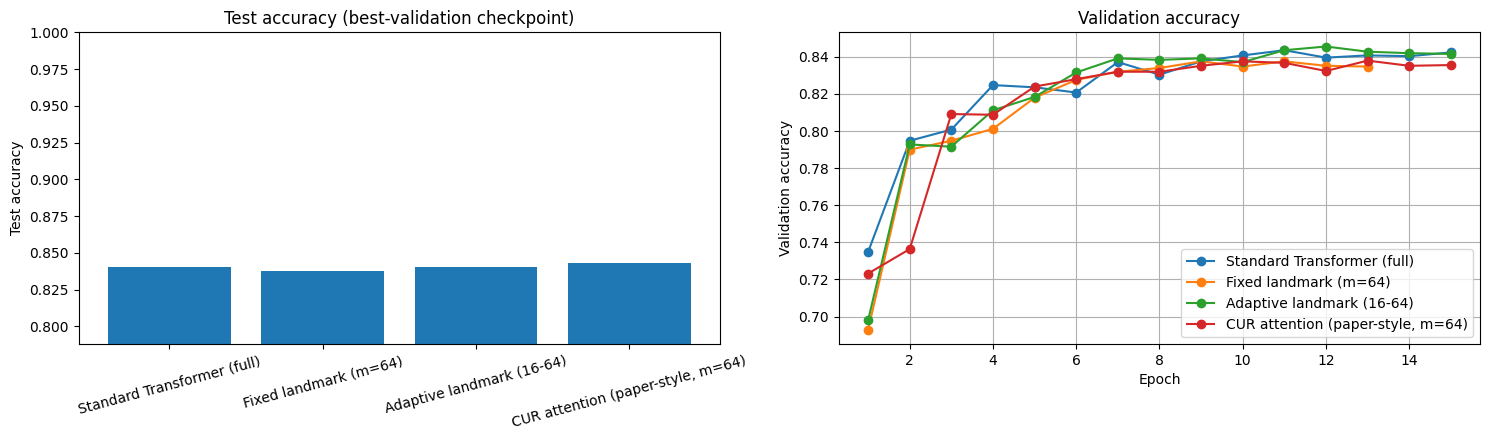

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

comparison = pd.DataFrame(results).drop(columns=["seed"])
display(comparison.round(4))

# analytical attention-score entries per head (NOT measured runtime)
n = SEQ_LEN
L = lengths.clone()
fixed_m = torch.minimum(torch.full_like(L, 64), L).mean().item()
adapt_m = torch.minimum(torch.clamp(torch.ceil(L / 64), 16, 64), L).mean().item()
entries = pd.DataFrame({
    "Model": list(MODEL_CONFIGS.keys()),
    "avg landmarks m": ["-", f"{fixed_m:.1f}", f"{adapt_m:.1f}", f"{fixed_m:.1f}"],
    "score entries / head": [n * n, int(n * fixed_m), int(n * adapt_m), int(2 * n * fixed_m + fixed_m ** 2)],
})
entries["vs full attention"] = (entries["score entries / head"] / (n * n)).map("{:.2%}".format)
print("\nAnalytical attention-score sizes (not a guaranteed runtime / memory reduction):")
display(entries)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(comparison["model"], comparison["test_accuracy"])
ax[0].set_ylim(max(0.5, comparison["test_accuracy"].min() - 0.05), 1.0)
ax[0].set_ylabel("Test accuracy"); ax[0].set_title("Test accuracy (best-validation checkpoint)")
ax[0].tick_params(axis="x", rotation=15)
for name, h in histories.items():
    hd = pd.DataFrame(h); ax[1].plot(hd["epoch"], hd["val_accuracy"], marker="o", label=name)
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Validation accuracy"); ax[1].set_title("Validation accuracy"); ax[1].grid(True); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Confusion matrix and report for the model with the best VALIDATION accuracy
best = max(results, key=lambda r: r["val_accuracy"])["model"]
model = trained_models[best].eval()
preds, labs = [], []
with torch.no_grad():
    for X, y in test_loader:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            preds.append(model(X.to(device).long()).argmax(1).cpu())
        labs.append(y)
preds, labs = torch.cat(preds).numpy(), torch.cat(labs).numpy()
print("Model:", best)
print(confusion_matrix(labs, preds))
print(classification_report(labs, preds, target_names=["Negative", "Positive"], digits=4))

Model: Adaptive landmark (16-64)
[[10438  2062]
 [ 1922 10578]]
              precision    recall  f1-score   support

    Negative     0.8445    0.8350    0.8397     12500
    Positive     0.8369    0.8462    0.8415     12500

    accuracy                         0.8406     25000
   macro avg     0.8407    0.8406    0.8406     25000
weighted avg     0.8407    0.8406    0.8406     25000



## 7. Optional: repeated seeds and landmark-count ablation (set the flags to `True`; these take much longer)

In [ ]:
RUN_MULTI_SEED = False
SEEDS = [42, 123, 456]
RUN_ABLATION = False
ABLATION_M = [16, 32, 64, 128]

seed_df, ablation_df = None, None

if RUN_MULTI_SEED:
    rows = []
    for name, cfg in MODEL_CONFIGS.items():
        for s in SEEDS:
            print(f"{name} | seed {s}")
            _, r, _ = train_and_eval(name, cfg, seed=s, verbose=False)
            rows.append(r)
    seed_df = pd.DataFrame(rows)
    display(seed_df.groupby("model")[["test_accuracy", "test_f1"]].agg(["mean", "std"]).round(4))

if RUN_ABLATION:
    rows = []
    for m_val in ABLATION_M:
        print(f"fixed landmark m = {m_val}")
        _, r, _ = train_and_eval(f"Fixed landmark (m={m_val})", dict(mode="fixed", m=m_val), verbose=False)
        r["m"] = m_val; rows.append(r)
    ablation_df = pd.DataFrame(rows)
    display(ablation_df[["m", "test_accuracy", "test_f1", "train_sec_per_epoch", "peak_mem_gb"]].round(4))
    plt.plot(ablation_df["m"], ablation_df["test_accuracy"], marker="o")
    plt.xlabel("Number of landmarks m"); plt.ylabel("Test accuracy"); plt.grid(True);
    plt.show()

## 8. Save results and try your own review

In [ ]:
out_dir = "Transformer_Research_Results_v2"
os.makedirs(out_dir, exist_ok=True)
comparison.to_csv(f"{out_dir}/model_comparison.csv", index=False)
entries.to_csv(f"{out_dir}/attention_entries.csv", index=False)
if seed_df is not None: seed_df.to_csv(f"{out_dir}/multi_seed_results.csv", index=False)
if ablation_df is not None: ablation_df.to_csv(f"{out_dir}/ablation_results.csv", index=False)
for name, mdl in trained_models.items():
    torch.save(mdl.state_dict(), f"{out_dir}/" + name.split(" (")[0].lower().replace(" ", "_") + ".pt")
with open(f"{out_dir}/config.json", "w") as f:
    json.dump({k: globals()[k] for k in ["MAX_LENGTH", "D_MODEL", "N_HEADS", "N_LAYERS", "DIM_FF", "DROPOUT",
               "CONV_KERNEL", "STEM_STRIDE", "BATCH_SIZE", "EPOCHS", "PATIENCE", "LEARNING_RATE", "WEIGHT_DECAY",
               "LABEL_SMOOTHING", "TOKEN_MASK_PROB", "LOWERCASE", "HEAD_TAIL_TRUNCATION", "SEED"]}, f, indent=2)
print("Saved to", out_dir)

def predict_review(text):
    ids = encode_many([text]).to(device).long()
    print(f"Review: {text[:120]}...\n")
    for name, mdl in trained_models.items():
        mdl.eval()
        with torch.no_grad():
            p = mdl(ids).softmax(-1)[0]
        print(f"{name:38s} -> {'Positive' if p[1] > p[0] else 'Negative'}  (P(pos) = {p[1]:.2%})")

predict_review("A wonderful film with brilliant acting and a story that kept me hooked until the very last minute.")
predict_review("Boring, predictable and badly acted. I wanted my two hours back.")

Saved to Transformer_Research_Results_v2
Review: A wonderful film with brilliant acting and a story that kept me hooked until the very last minute....

Standard Transformer (full)            -> Positive  (P(pos) = 98.85%)
Fixed landmark (m=64)                  -> Positive  (P(pos) = 97.51%)
Adaptive landmark (16-64)              -> Positive  (P(pos) = 99.21%)
CUR attention (paper-style, m=64)      -> Positive  (P(pos) = 97.16%)
Review: Boring, predictable and badly acted. I wanted my two hours back....

Standard Transformer (full)            -> Negative  (P(pos) = 1.10%)
Fixed landmark (m=64)                  -> Negative  (P(pos) = 0.52%)
Adaptive landmark (16-64)              -> Negative  (P(pos) = 0.28%)
CUR attention (paper-style, m=64)      -> Negative  (P(pos) = 1.31%)
